# Adult Census Income — Experimentos com Random Forest

Este notebook dá continuidade ao estudo anterior sobre a base **Adult Census Income** (`adult.csv`), substituindo o classificador de árvore única (`DecisionTreeClassifier`) pelo *ensemble* de florestas aleatórias (`RandomForestClassifier`).

### Protocolo Experimental (idêntico aos notebooks `03` e `04`)
Para garantir uma comparação justa e direta com os resultados obtidos anteriormente pela Árvore de Decisão, mantemos rigorosamente o mesmo protocolo experimental definido em `experimentos/comum.py`:
- **Limpeza dos dados:** remoção das 24 duplicatas exatas e dos 2.398 registros com valores ausentes (`?`), resultando em **30.139 registros completos**.
- **Atributos preditores (12 colunas):** exclusão de `peso_amostral` (`fnlwgt`, artefato censitário sem poder preditivo individual) e de `escolaridade` textual (redundante com `escolaridade_num`). As variáveis categóricas são codificadas dentro de um `Pipeline` (testando `OneHotEncoder`, `OrdinalEncoder` e `TargetEncoder` como hiperparâmetro de pré-processamento), evitando vazamento de dados (*data leakage*) entre os folds.
- **Partição estratificada (70% / 30%):** semente fixa `SEED = 42`, gerando **21.097 registros de treino** e **9.042 registros de teste**.
- **Validação cruzada:** `StratifiedKFold` de **5 folds** embaralhados (`SEED = 42`) aplicados exclusivamente sobre o conjunto de treino.
- **Critério de seleção:** o melhor modelo de cada busca é selecionado pela **acurácia média na validação cruzada**, registrando em paralelo a **acurácia balanceada**, **precisão (precision)**, **revocação (recall)**, **F1-score** (da classe positiva `> 50 mil`) e **ROC-AUC**.

### Estrutura do Notebook
1. **Configuração do Ambiente, Codificadores e Funções Auxiliares**
2. **Carregamento e Partição dos Dados**
3. **Modelos de Referência: Árvores de Decisão (Inicial e Otimizada) vs. Random Forest Inicial**
4. **Busca em Grade (`GridSearchCV` — incluindo escolha da codificação)**
5. **Busca Aleatória (`RandomizedSearchCV` — incluindo escolha da codificação)**
6. **Otimização Bayesiana (`Optuna TPE` — incluindo escolha da codificação)**
7. **Comparação das Estratégias e Seleção do Melhor Modelo (Validação Cruzada e Teste)**
8. **Curva de Validação: Número de Árvores (`n_estimators`) na Floresta Otimizada**
9. **Análise de Erros: Matriz de Confusão e Curva ROC**
10. **Importância dos Atributos (Permutação vs. Impureza de Gini)**
11. **Persistência dos Resultados**

## 1. Configuração do Ambiente, Codificadores e Funções Auxiliares

Importamos as bibliotecas necessárias (incluindo o `optuna` para a Otimização Bayesiana) e conectamos o notebook aos módulos compartilhados do projeto (`experimentos/comum.py` e `graficos.py`).

Para permitir que a **estratégia de codificação das variáveis categóricas** (`"onehot"`, `"ordinal"` ou `"target"`) seja otimizada diretamente como um hiperparâmetro do `Pipeline` tanto no `GridSearchCV` e `RandomizedSearchCV` quanto no `Optuna`, definimos o transformador `PreprocessadorRF`.

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=UserWarning, module="sklearn.utils.parallel")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import randint
import optuna

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    auc,
    classification_report,
    confusion_matrix,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, TargetEncoder
from sklearn.tree import DecisionTreeClassifier

# Adiciona o diretório 'experimentos' ao path para importar o protocolo comum
sys.path.insert(0, "experimentos")
import comum
from graficos import (
    AZUL,
    AZUL_CLARO,
    CINZA_OUTROS,
    TEXTO_SEC,
    configurar_estilo,
    eixo_percentual,
    formatar_int,
    formatar_pct,
    grafico_metricas,
    mostrar,
)

configurar_estilo()
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Configurações de execução (N_JOBS controla o paralelismo; RAPIDO=1 reduz a busca para testes rápidos)
N_JOBS = int(os.environ.get("N_JOBS", "-1"))
RAPIDO = os.environ.get("RAPIDO", "0") == "1"

NOMES_METRICAS = {
    "acuracia": "Acurácia",
    "acuracia_bal": "Acurácia balanceada",
    "precisao": "Precision (> 50 mil)",
    "revocacao": "Recall (> 50 mil)",
    "f1": "F1 (> 50 mil)",
    "roc_auc": "ROC-AUC",
}


def pct(x, casas=2):
    """Converte proporção (0 a 1) para percentual arredondado."""
    return round(float(x) * 100, casas)


print(f"Ambiente configurado com sucesso | SEED = {comum.SEED} | N_JOBS = {N_JOBS} | Modo Rápido = {RAPIDO}")

Ambiente configurado com sucesso | SEED = 42 | N_JOBS = -1 | Modo Rápido = False


In [2]:
class PreprocessadorRF(BaseEstimator, TransformerMixin):
    """Transformador que aplica a codificação categórica escolhida ('onehot', 'ordinal' ou 'target')
    dentro do Pipeline de validação cruzada, mantendo as variáveis numéricas sem alteração."""

    def __init__(self, codificacao="onehot"):
        self.codificacao = codificacao

    def _criar_encoder(self):
        if self.codificacao == "onehot":
            return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        elif self.codificacao == "ordinal":
            return OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
        elif self.codificacao == "target":
            return TargetEncoder(cv=comum.validacao_cruzada(comum.SEED))
        raise ValueError(f"Codificação desconhecida: {self.codificacao}")

    def fit(self, X, y=None):
        numericas, categoricas = comum.colunas_por_tipo(X)
        self.ct_ = ColumnTransformer(
            [("num", "passthrough", numericas), ("cat", self._criar_encoder(), categoricas)],
            verbose_feature_names_out=False,
        )
        self.ct_.fit(X, y)
        return self

    def transform(self, X):
        return self.ct_.transform(X)

    def fit_transform(self, X, y=None):
        numericas, categoricas = comum.colunas_por_tipo(X)
        self.ct_ = ColumnTransformer(
            [("num", "passthrough", numericas), ("cat", self._criar_encoder(), categoricas)],
            verbose_feature_names_out=False,
        )
        return self.ct_.fit_transform(X, y)

    def get_feature_names_out(self, input_features=None):
        return self.ct_.get_feature_names_out(input_features)


def montar_rf(modelo, codificacao="onehot"):
    """Monta o Pipeline com PreprocessadorRF + RandomForestClassifier."""
    return Pipeline([
        ("prep", PreprocessadorRF(codificacao=codificacao)),
        ("modelo", modelo),
    ])


def construir_rf_de_params(params, n_jobs=N_JOBS):
    """Reconstrói o Pipeline de Random Forest a partir de um dicionário de melhores parâmetros."""
    p = dict(params)
    cod = p.pop("codificacao", "onehot")
    return montar_rf(
        RandomForestClassifier(**p, random_state=comum.SEED, n_jobs=n_jobs),
        codificacao=cod,
    )


def registrar(nome, busca, X_te, y_te, duracao, n_candidatos):
    """Extrai e formata as métricas de validação cruzada e de teste do melhor candidato de uma busca."""
    pipe = busca.best_estimator_
    teste = comum.avaliar_teste(pipe, X_te, y_te)
    res = busca.cv_results_
    i = busca.best_index_

    cv = {
        m: float(res[f"mean_test_{m}"][i])
        for m in comum.METRICAS
    }
    cv.update({
        f"{m}_std": float(res[f"std_test_{m}"][i])
        for m in comum.METRICAS
    })

    melhores = {
        k.replace("modelo__", "").replace("prep__", ""): v
        for k, v in busca.best_params_.items()
    }

    comum.log(
        f"{nome}: "
        f"CV acc {cv['acuracia']*100:.2f} ± {cv['acuracia_std']*100:.2f}% | "
        f"Teste acc {teste['acuracia']*100:.2f}% | "
        f"F1 {teste['f1']*100:.2f}% | "
        f"AUC {teste['roc_auc']*100:.2f}% | "
        f"{n_candidatos} candidatos em {duracao:.1f}s"
    )

    return {
        "estrategia": nome,
        "melhores_parametros": melhores,
        "n_candidatos": int(n_candidatos),
        "n_ajustes": int(n_candidatos * comum.FOLDS),
        "tempo_s": float(duracao),
        "cv": cv,
        "teste": teste,
    }


def gerar_matriz_confusao(modelo, X_te, y_te):
    """Calcula a matriz de confusão no conjunto de teste e retorna as contagens (TN, FP, FN, TP)."""
    y_pred = modelo.predict(X_te)
    cm = confusion_matrix(y_te, y_pred)
    return {
        "tn": int(cm[0, 0]),
        "fp": int(cm[0, 1]),
        "fn": int(cm[1, 0]),
        "tp": int(cm[1, 1]),
    }


def gerar_roc(modelo, X_te, y_te):
    """Calcula os pontos da curva ROC (FPR, TPR) e a área sob a curva (AUC) no conjunto de teste."""
    probs = modelo.predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, probs)
    roc_auc = auc(fpr, tpr)
    return {
        "fpr": fpr.tolist(),
        "tpr": tpr.tolist(),
        "auc": float(roc_auc),
    }


def gerar_importancias(modelo, X_originais=None):
    """Extrai a importância dos atributos pela redução média de impureza (Gini/MDI) da Random Forest,
    agregando as colunas codificadas de volta aos 12 atributos originais."""
    rf = modelo.named_steps["modelo"]
    nomes_codificados = np.asarray(modelo[:-1].get_feature_names_out())
    importancias_brutas = rf.feature_importances_

    if X_originais is not None:
        originais = list(X_originais.columns)

        def coluna_original(nome):
            return next(
                c for c in sorted(originais, key=len, reverse=True)
                if nome == c or nome.startswith(c + "_")
            )

        agrupado = (
            pd.Series(importancias_brutas, index=[coluna_original(n) for n in nomes_codificados])
            .groupby(level=0)
            .sum()
            .sort_values(ascending=False)
        )
        return {k: float(v) for k, v in agrupado.items()}

    serie = pd.Series(importancias_brutas, index=nomes_codificados).sort_values(ascending=False)
    return {k: float(v) for k, v in serie.items()}

## 2. Carregamento e Partição dos Dados

Carregamos o dataset `adult.csv` por meio de `comum.carregar_dados()`, que traduz os nomes das colunas e categorias para o português, remove as 24 duplicatas e descarta os 2.398 registros com valores ausentes. Em seguida, separamos a variável-alvo `renda` (`> 50 mil` = 1) e realizamos a partição estratificada 70/30.

In [3]:
comum.log("Iniciando Experimento Random Forest")

comum.CAMINHO_DADOS = Path("adult.csv")
df = comum.carregar_dados()
X, y = comum.separar_xy(df)
X_tr, X_te, y_tr, y_te = comum.dividir(X, y)
cv = comum.validacao_cruzada()

# Dicionário que armazenará todos os resultados do experimento
saida = {
    "experimento": "random_forest",
    "n_treino": int(len(X_tr)),
    "n_teste": int(len(X_te)),
    "estrategias": [],
}

resumo_dados = pd.DataFrame([
    {"Conjunto": "Total (após limpeza)", "Registros": len(df), "Proporção > 50 mil (%)": pct(y.mean())},
    {"Conjunto": "Treino (70%)", "Registros": len(X_tr), "Proporção > 50 mil (%)": pct(y_tr.mean())},
    {"Conjunto": "Teste (30%)", "Registros": len(X_te), "Proporção > 50 mil (%)": pct(y_te.mean())},
]).set_index("Conjunto")

print(f"Atributos de entrada (antes da codificação): {X_tr.shape[1]} colunas -> {list(X_tr.columns)}")
display(resumo_dados)

[11:11:40] Iniciando Experimento Random Forest


Atributos de entrada (antes da codificação): 12 colunas -> ['idade', 'classe_trabalho', 'escolaridade_num', 'estado_civil', 'ocupacao', 'relacao_familiar', 'raca', 'sexo', 'ganho_capital', 'perda_capital', 'horas_semana', 'pais_origem']


,Registros,Proporção > 50 mil (%)
Conjunto,,
Total (após limpeza),30139,24.90
Treino (70%),21097,24.90
Teste (30%),9042,24.91


## 3. Modelos de Referência: Árvores de Decisão vs. Random Forest Inicial

No estudo anterior com Árvore de Decisão (notebooks `03` e `04`), estabelecemos dois marcos principais de referência:
1. **Árvore de Decisão Inicial (`nb 03`):** hiperparâmetros fixados a priori (`max_depth = 7`, `min_samples_leaf = 10`, `min_samples_split = 20`, codificação `onehot`).
2. **Árvore de Decisão Otimizada (`nb 04`):** melhor árvore obtida após os experimentos de otimização de hiperparâmetros (`Exp. 3: TPE, seed 1`, com `max_depth = 23`, `min_samples_leaf = 3`, `min_samples_split = 25`, `max_features = 0.8`, `ccp_alpha ≈ 2,49e-4`, codificação `onehot`).

Para estabelecer uma linha de base diretamente comparável para o comitê, definimos a **Random Forest Inicial** com os mesmos parâmetros de regularização da Árvore Inicial (`max_depth = 7`, `min_samples_leaf = 10`, `min_samples_split = 20`, `codificacao = "onehot"`) e `n_estimators = 100` árvores. Avaliamos os três modelos sob a mesma validação cruzada de 5 folds e no conjunto de teste.

In [4]:
# 3.1 Árvore de Decisão Inicial (referência do notebook 03)
arvore_inicial = comum.construir_arvore(comum.PARAMETROS_ARVORE_ANTERIOR, X_tr)
cv_arvore_ini = comum.avaliar_cv(arvore_inicial, X_tr, y_tr, n_jobs=N_JOBS)
arvore_inicial.fit(X_tr, y_tr)
teste_arvore_ini = comum.avaliar_teste(arvore_inicial, X_te, y_te)

# 3.2 Árvore de Decisão Otimizada (melhor modelo do notebook 04 — TPE, seed 1)
bay_arv = comum.carregar_resultado("arvore_bayesiana")
melhor_exec_arv = max(bay_arv["execucoes"], key=lambda e: e["cv"]["acuracia"])
PARAM_ARVORE_OTIM = melhor_exec_arv["melhores_parametros"]
arvore_otim = comum.construir_arvore(PARAM_ARVORE_OTIM, X_tr)
cv_arvore_otim = melhor_exec_arv["cv"]
arvore_otim.fit(X_tr, y_tr)
teste_arvore_otim = comum.avaliar_teste(arvore_otim, X_te, y_te)

# 3.3 Random Forest Inicial
PARAM_RF = {
    "codificacao": "onehot",
    "n_estimators": 100,
    "max_depth": 7,
    "min_samples_leaf": 10,
    "min_samples_split": 20,
}

rf_inicial = construir_rf_de_params(PARAM_RF, n_jobs=N_JOBS)
cv_ini = comum.avaliar_cv(rf_inicial, X_tr, y_tr, n_jobs=N_JOBS)
rf_inicial.fit(X_tr, y_tr)
teste_ini = comum.avaliar_teste(rf_inicial, X_te, y_te)

saida["modelo_inicial"] = {
    "parametros": PARAM_RF,
    "cv": cv_ini,
    "teste": teste_ini,
}
saida["arvore_otimizada_ref"] = {
    "parametros": PARAM_ARVORE_OTIM,
    "n_candidatos": melhor_exec_arv["n_candidatos"],
    "n_ajustes": melhor_exec_arv["n_ajustes"],
    "tempo_s": melhor_exec_arv["tempo_s"],
    "cv": cv_arvore_otim,
    "teste": teste_arvore_otim,
}

comum.log(
    f"Random Forest Inicial: CV acc {cv_ini['acuracia']*100:.2f} ± {cv_ini['acuracia_std']*100:.2f}% | "
    f"Teste acc {teste_ini['acuracia']*100:.2f}% | F1 {teste_ini['f1']*100:.2f}% | AUC {teste_ini['roc_auc']*100:.2f}%"
)

# Tabela comparativa das linhas de base: Árvore Inicial, Árvore Otimizada e Random Forest Inicial
tab_ref = pd.DataFrame({
    "Árvore Inicial (CV %)": {NOMES_METRICAS[m]: f"{pct(cv_arvore_ini[m]):.2f} ± {pct(cv_arvore_ini[f'{m}_std']):.2f}" for m in comum.METRICAS},
    "Árvore Otimizada (CV %)": {NOMES_METRICAS[m]: f"{pct(cv_arvore_otim[m]):.2f} ± {pct(cv_arvore_otim[f'{m}_std']):.2f}" for m in comum.METRICAS},
    "RF Inicial (CV %)": {NOMES_METRICAS[m]: f"{pct(cv_ini[m]):.2f} ± {pct(cv_ini[f'{m}_std']):.2f}" for m in comum.METRICAS},
    "Árvore Inicial (Teste %)": {NOMES_METRICAS[m]: pct(teste_arvore_ini[m]) for m in comum.METRICAS},
    "Árvore Otimizada (Teste %)": {NOMES_METRICAS[m]: pct(teste_arvore_otim[m]) for m in comum.METRICAS},
    "RF Inicial (Teste %)": {NOMES_METRICAS[m]: pct(teste_ini[m]) for m in comum.METRICAS},
})
display(tab_ref)

[11:11:48] Random Forest Inicial: CV acc 84.52 ± 0.61% | Teste acc 85.22% | F1 63.81% | AUC 90.66%


,Árvore Inicial (CV %),Árvore Otimizada (CV %),RF Inicial (CV %),Árvore Inicial (Teste %),Árvore Otimizada (Teste %),RF Inicial (Teste %)
Acurácia,84.82 ± 0.52,85.27 ± 0.47,84.52 ± 0.61,85.34,85.43,85.22
Acurácia balanceada,74.34 ± 1.03,77.27 ± 0.93,72.45 ± 1.46,75.03,76.59,74.23
Precision (> 50 mil),78.79 ± 1.69,75.00 ± 1.42,82.15 ± 1.62,80.30,77.16,81.81
Recall (> 50 mil),53.46 ± 2.24,61.32 ± 2.12,48.40 ± 3.27,54.48,58.97,52.31
F1 (> 50 mil),63.67 ± 1.63,67.45 ± 1.34,60.83 ± 2.48,64.92,66.85,63.81
ROC-AUC,89.58 ± 0.24,89.92 ± 0.34,90.19 ± 0.23,90.34,90.34,90.66


## 4. Busca em Grade (`GridSearchCV`)

Avaliamos de forma exaustiva uma grade de hiperparâmetros da Random Forest combinada com as três estratégias de codificação de variáveis categóricas:
- `prep__codificacao`: `["onehot", "ordinal", "target"]`
- `modelo__n_estimators`: `[100, 200]`
- `modelo__max_depth`: `[5, 10, 20]`
- `modelo__min_samples_leaf`: `[1, 2]`
- `modelo__min_samples_split`: `[2, 5]`
- `modelo__max_features`: `["sqrt", None]`
- `modelo__class_weight`: `[None, "balanced"]`

Isso totaliza **288 combinações** (1.440 ajustes considerando os 5 folds da validação cruzada). O modelo é selecionado pela maior acurácia média de validação (`refit="acuracia"`).

In [5]:
grade = {
    "prep__codificacao": ["onehot", "ordinal", "target"],
    "modelo__n_estimators": [100, 200],
    "modelo__max_depth": [5, 10, 20],
    "modelo__min_samples_leaf": [1, 2],
    "modelo__min_samples_split": [2, 5],
    "modelo__max_features": ["sqrt", None],
    "modelo__class_weight": [None, "balanced"],
}

if RAPIDO:
    grade = {k: v[:2] for k, v in grade.items()}

n_grade = int(np.prod([len(v) for v in grade.values()]))

base = montar_rf(
    RandomForestClassifier(
        random_state=comum.SEED,
    ),
    codificacao="onehot",
)

t0 = time.perf_counter()
gs = GridSearchCV(
    base,
    grade,
    cv=cv,
    scoring=comum.METRICAS,
    refit="acuracia",
    n_jobs=N_JOBS,
)
gs.fit(X_tr, y_tr)
tempo_gs = time.perf_counter() - t0

reg_gs = registrar("grid_search", gs, X_te, y_te, tempo_gs, n_grade)
saida["estrategias"].append(reg_gs)

print("\nMelhores hiperparâmetros (Grid Search):", reg_gs["melhores_parametros"])
print("\nTop 10 candidatos da Busca em Grade (ordenados pela acurácia na validação cruzada):")
display(comum.resumo_busca(gs, 10))

[11:06:48] grid_search: CV acc 85.94 ± 0.21% | Teste acc 86.25% | F1 69.59% | AUC 91.88% | 288 candidatos em 589.8s



Melhores hiperparâmetros (Grid Search): {'class_weight': None, 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100, 'codificacao': 'ordinal'}

Top 10 candidatos da Busca em Grade (ordenados pela acurácia na validação cruzada):


,param_modelo__class_weight,param_modelo__max_depth,param_modelo__max_features,param_modelo__min_samples_leaf,param_modelo__min_samples_split,param_modelo__n_estimators,param_prep__codificacao,mean_test_acuracia,std_test_acuracia,mean_test_acuracia_bal,std_test_acuracia_bal,mean_test_precisao,std_test_precisao,mean_test_revocacao,std_test_revocacao,mean_test_f1,std_test_f1,mean_test_roc_auc,std_test_roc_auc,mean_fit_time
0,None,20,sqrt,2,5,100,ordinal,0.859364,0.002133,0.778768,0.005516,0.771831,0.007220,0.618195,0.013447,0.686390,0.007280,0.913395,0.003088,1.793694
1,None,10,None,2,5,200,target,0.858984,0.004542,0.773362,0.009984,0.781108,0.009117,0.602775,0.021678,0.680218,0.014235,0.912889,0.003624,9.695670
2,None,10,None,1,5,200,target,0.858842,0.004541,0.773459,0.009857,0.780058,0.008121,0.603346,0.021087,0.680215,0.014154,0.912767,0.003599,9.395160
3,None,10,None,1,2,200,target,0.858795,0.004238,0.773681,0.009684,0.779372,0.008200,0.604107,0.021278,0.680410,0.013656,0.912861,0.003619,10.736947
4,None,10,None,2,2,200,target,0.858747,0.004490,0.773205,0.009819,0.780131,0.008847,0.602775,0.021239,0.679861,0.014009,0.912838,0.003597,11.318136
5,None,10,None,1,2,100,target,0.858747,0.005775,0.772759,0.010952,0.781128,0.013141,0.601442,0.022570,0.679376,0.016282,0.912480,0.003815,5.231591
6,None,20,sqrt,2,2,100,ordinal,0.858700,0.002203,0.777881,0.004626,0.770411,0.012337,0.616862,0.013216,0.684932,0.005677,0.912947,0.002803,2.000694
7,None,10,None,1,5,100,target,0.858700,0.005524,0.772855,0.011119,0.780592,0.010881,0.601822,0.023178,0.679416,0.016344,0.912352,0.003844,5.521623
8,None,10,None,2,5,100,target,0.858700,0.005465,0.772346,0.011001,0.781726,0.011138,0.600300,0.023018,0.678866,0.016193,0.912647,0.003830,5.658300
9,None,10,None,2,2,100,target,0.858652,0.005240,0.772060,0.011089,0.782089,0.009956,0.599538,0.023577,0.678497,0.016150,0.912528,0.003777,5.539529


## 5. Busca Aleatória (`RandomizedSearchCV`)

A Busca Aleatória sorteia `n_iter = 50` candidatos (ou `10` no modo rápido) em um espaço contínuo/discreto mais amplo de hiperparâmetros, incluindo a escolha da codificação categórica:
- `prep__codificacao`: `["onehot", "ordinal", "target"]`
- `modelo__n_estimators`: `randint(50, 200)`
- `modelo__max_depth`: `randint(3, 40)`
- `modelo__min_samples_leaf`: `randint(1, 30)`
- `modelo__min_samples_split`: `randint(2, 50)`
- `modelo__max_features`: `["sqrt", "log2", None]`
- `modelo__class_weight`: `[None, "balanced"]`

In [6]:
distribuicoes = {
    "prep__codificacao": ["onehot", "ordinal", "target"],
    "modelo__n_estimators": randint(50, 200),
    "modelo__max_depth": randint(3, 40),
    "modelo__min_samples_leaf": randint(1, 30),
    "modelo__min_samples_split": randint(2, 50),
    "modelo__max_features": ["sqrt", "log2", None],
    "modelo__class_weight": [None, "balanced"],
}

n_iter = 10 if RAPIDO else 50

t0 = time.perf_counter()
rs = RandomizedSearchCV(
    base,
    distribuicoes,
    n_iter=n_iter,
    cv=cv,
    scoring=comum.METRICAS,
    refit="acuracia",
    n_jobs=N_JOBS,
    random_state=comum.SEED,
)
rs.fit(X_tr, y_tr)
tempo_rs = time.perf_counter() - t0

reg_rs = registrar("random_search", rs, X_te, y_te, tempo_rs, n_iter)
saida["estrategias"].append(reg_rs)

print("\nMelhores hiperparâmetros (Random Search):", reg_rs["melhores_parametros"])
print("\nTop 10 candidatos da Busca Aleatória (ordenados pela acurácia na validação cruzada):")
display(comum.resumo_busca(rs, 10))

[11:07:58] random_search: CV acc 85.77 ± 0.23% | Teste acc 86.14% | F1 68.40% | AUC 92.04% | 50 candidatos em 69.7s



Melhores hiperparâmetros (Random Search): {'class_weight': None, 'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 41, 'n_estimators': 181, 'codificacao': 'ordinal'}

Top 10 candidatos da Busca Aleatória (ordenados pela acurácia na validação cruzada):


,param_modelo__class_weight,param_modelo__max_depth,param_modelo__max_features,param_modelo__min_samples_leaf,param_modelo__min_samples_split,param_modelo__n_estimators,param_prep__codificacao,mean_test_acuracia,std_test_acuracia,mean_test_acuracia_bal,std_test_acuracia_bal,mean_test_precisao,std_test_precisao,mean_test_revocacao,std_test_revocacao,mean_test_f1,std_test_f1,mean_test_roc_auc,std_test_roc_auc,mean_fit_time
0,None,16,sqrt,4,41,181,ordinal,0.857705,0.002348,0.767486,0.008098,0.787179,0.005981,0.587740,0.019683,0.672726,0.010874,0.914028,0.003191,3.551864
1,None,35,None,5,43,90,target,0.856282,0.004533,0.774679,0.010272,0.763971,0.008065,0.612100,0.022488,0.679414,0.014393,0.911104,0.004111,5.235155
2,None,15,sqrt,3,40,186,ordinal,0.856235,0.002568,0.764346,0.008763,0.786011,0.007593,0.581270,0.021472,0.667974,0.011976,0.914027,0.003281,3.408827
3,None,19,None,6,25,118,ordinal,0.856141,0.001888,0.773441,0.007032,0.765763,0.004184,0.608676,0.017265,0.678052,0.009033,0.909162,0.004211,4.582284
4,None,20,log2,12,35,63,target,0.855714,0.004644,0.769212,0.011729,0.772077,0.004691,0.596873,0.026055,0.672936,0.016542,0.913351,0.003023,1.567793
5,None,35,None,10,45,108,ordinal,0.855619,0.002177,0.772076,0.007465,0.765776,0.004178,0.605631,0.018072,0.676151,0.009747,0.909230,0.004062,4.373588
6,None,21,None,20,42,177,target,0.855287,0.004188,0.771218,0.009525,0.765889,0.010979,0.603726,0.021759,0.674913,0.013326,0.910945,0.003670,8.858397
7,None,39,sqrt,17,47,144,target,0.855145,0.004486,0.765971,0.011400,0.775988,0.006898,0.588308,0.025652,0.668882,0.016279,0.913183,0.003357,2.816327
8,None,34,None,17,33,181,ordinal,0.854671,0.001882,0.770300,0.006762,0.764442,0.006159,0.602205,0.016917,0.673492,0.008733,0.909076,0.004089,7.070967
9,None,18,log2,16,3,178,ordinal,0.854624,0.003432,0.761874,0.008948,0.782138,0.005167,0.577083,0.020242,0.663913,0.012946,0.912208,0.003320,2.590280


## 6. Otimização Bayesiana (`Optuna TPE`)

Assim como realizado no estudo da Árvore de Decisão, aplicamos a **Otimização Bayesiana** via amostrador **TPE (*Tree-structured Parzen Estimator*)** do `Optuna` (`n_trials = 50`). Diferentemente da Busca em Grade e da Busca Aleatória (que avaliam pontos de maneira independente), o TPE modela a distribuição probabilística dos hiperparâmetros promissores a partir do histórico das tentativas anteriores, concentrando a busca nas regiões de maior acurácia de validação cruzada.

Espaço de busca explorado pelo TPE:
- `codificacao`: `["onehot", "ordinal", "target"]`
- `n_estimators`: inteiro entre `50` e `300`
- `max_depth`: inteiro entre `5` e `40`
- `min_samples_leaf`: inteiro entre `1` e `30` (escala logarítmica)
- `min_samples_split`: inteiro entre `2` e `50` (escala logarítmica)
- `max_features`: `["sqrt", "log2", 0.5, 0.8, None]`
- `criterion`: `["gini", "entropy"]`
- `class_weight`: `[None, "balanced", "balanced_subsample"]`

[11:09:32] optuna_tpe: CV acc 86.01 ± 0.30% | Teste acc 86.62% | F1 70.28% | AUC 92.16% | 50 candidatos em 93.2s (melhor na tentativa #35)



Melhores hiperparâmetros (Optuna TPE): {'codificacao': 'ordinal', 'n_estimators': 70, 'max_depth': 23, 'min_samples_leaf': 1, 'min_samples_split': 25, 'max_features': 'log2', 'criterion': 'entropy', 'class_weight': None}

Top 10 candidatos da Otimização Bayesiana (Optuna TPE):


,tentativa,param_codificacao,param_n_estimators,param_max_depth,param_min_samples_leaf,param_min_samples_split,param_max_features,param_criterion,param_class_weight,mean_test_acuracia,std_test_acuracia,mean_test_acuracia_bal,mean_test_precisao,mean_test_revocacao,mean_test_f1,mean_test_roc_auc,mean_fit_time
0,35,ordinal,70,23,1,25,log2,entropy,None,0.860122,0.003034,0.779464,0.774494,0.618765,0.687750,0.914312,0.413666
1,42,ordinal,77,24,1,38,log2,entropy,None,0.859790,0.001305,0.778353,0.774987,0.616102,0.686347,0.914477,0.427099
2,43,ordinal,107,25,1,45,log2,entropy,None,0.859506,0.002445,0.778227,0.773684,0.616291,0.685950,0.915053,0.611430
3,49,ordinal,72,26,2,29,log2,entropy,None,0.859174,0.002345,0.778834,0.770730,0.618767,0.686240,0.914240,0.419629
4,32,target,95,14,1,24,0.8,entropy,None,0.858889,0.004325,0.775462,0.776064,0.609246,0.682450,0.913525,1.011943
5,30,ordinal,127,23,1,33,log2,entropy,None,0.858748,0.001421,0.776640,0.773023,0.613055,0.683653,0.914814,0.576002
6,17,ordinal,113,17,2,16,0.8,entropy,None,0.858605,0.001690,0.776291,0.772858,0.612293,0.683143,0.911619,0.841414
7,41,ordinal,75,23,1,45,log2,entropy,None,0.858605,0.001648,0.776609,0.772298,0.613245,0.683460,0.914841,0.441862
8,45,ordinal,119,22,1,47,log2,entropy,None,0.858558,0.002146,0.774669,0.776243,0.607534,0.681374,0.915372,0.627986
9,19,ordinal,182,29,1,43,0.8,entropy,None,0.858463,0.001769,0.778804,0.767138,0.620095,0.685634,0.911904,1.418101


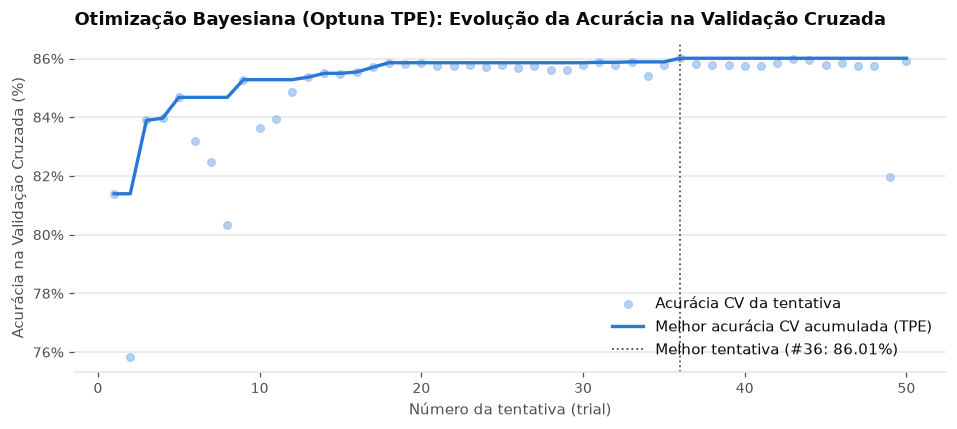

In [7]:
n_trials_optuna = 10 if RAPIDO else 50
historico_optuna = []


def espaco_optuna_rf(trial):
    return {
        "codificacao": trial.suggest_categorical("codificacao", ["onehot", "ordinal", "target"]),
        "n_estimators": trial.suggest_int("n_estimators", 50, 300),
        "max_depth": trial.suggest_int("max_depth", 5, 40),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 30, log=True),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 50, log=True),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5, 0.8, None]),
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy"]),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced", "balanced_subsample"]),
    }


def objetivo_optuna(trial):
    params = espaco_optuna_rf(trial)
    pipe = construir_rf_de_params(params, n_jobs=N_JOBS)
    res_cv = comum.avaliar_cv(pipe, X_tr, y_tr, cv=cv, n_jobs=N_JOBS)
    historico_optuna.append({
        "tentativa": trial.number,
        "parametros": params,
        **res_cv,
    })
    return res_cv["acuracia"]


sampler_tpe = optuna.samplers.TPESampler(seed=comum.SEED)
estudo_tpe = optuna.create_study(direction="maximize", sampler=sampler_tpe)

t0 = time.perf_counter()
estudo_tpe.optimize(objetivo_optuna, n_trials=n_trials_optuna)
tempo_optuna = time.perf_counter() - t0

melhor_trial_idx = estudo_tpe.best_trial.number
melhor_hist = historico_optuna[melhor_trial_idx]
melhores_params_optuna = melhor_hist["parametros"]

# Reajusta o melhor modelo do Optuna no conjunto de treino completo e avalia no teste
pipe_optuna = construir_rf_de_params(melhores_params_optuna, n_jobs=N_JOBS)
pipe_optuna.fit(X_tr, y_tr)
teste_optuna = comum.avaliar_teste(pipe_optuna, X_te, y_te)

cv_optuna = {m: float(melhor_hist[m]) for m in comum.METRICAS}
cv_optuna.update({f"{m}_std": float(melhor_hist[f"{m}_std"]) for m in comum.METRICAS})

valores_tentativas = np.array([h["acuracia"] for h in historico_optuna])
melhor_acumulado = np.maximum.accumulate(valores_tentativas)

reg_optuna = {
    "estrategia": "optuna_tpe",
    "melhores_parametros": melhores_params_optuna,
    "melhor_tentativa": int(melhor_trial_idx),
    "n_candidatos": int(n_trials_optuna),
    "n_ajustes": int(n_trials_optuna * comum.FOLDS),
    "tempo_s": float(tempo_optuna),
    "cv": cv_optuna,
    "teste": teste_optuna,
    "melhor_ate_a_tentativa": melhor_acumulado.tolist(),
}
saida["estrategias"].append(reg_optuna)

comum.log(
    f"optuna_tpe: "
    f"CV acc {cv_optuna['acuracia']*100:.2f} ± {cv_optuna['acuracia_std']*100:.2f}% | "
    f"Teste acc {teste_optuna['acuracia']*100:.2f}% | "
    f"F1 {teste_optuna['f1']*100:.2f}% | "
    f"AUC {teste_optuna['roc_auc']*100:.2f}% | "
    f"{n_trials_optuna} candidatos em {tempo_optuna:.1f}s (melhor na tentativa #{melhor_trial_idx})"
)

print("\nMelhores hiperparâmetros (Optuna TPE):", melhores_params_optuna)

# Tabela com o Top 10 candidatos da Otimização Bayesiana
df_optuna_top = pd.DataFrame([
    {
        "tentativa": h["tentativa"],
        **{f"param_{k}": v for k, v in h["parametros"].items()},
        "mean_test_acuracia": h["acuracia"],
        "std_test_acuracia": h["acuracia_std"],
        "mean_test_acuracia_bal": h["acuracia_bal"],
        "mean_test_precisao": h["precisao"],
        "mean_test_revocacao": h["revocacao"],
        "mean_test_f1": h["f1"],
        "mean_test_roc_auc": h["roc_auc"],
        "mean_fit_time": h["tempo_ajuste_s"],
    }
    for h in historico_optuna
]).sort_values("mean_test_acuracia", ascending=False).reset_index(drop=True)

print("\nTop 10 candidatos da Otimização Bayesiana (Optuna TPE):")
display(df_optuna_top.head(10))

# Gráfico de convergência da Otimização Bayesiana
fig, ax = plt.subplots(figsize=(8.8, 4.0))
tentativas_x = np.arange(1, len(valores_tentativas) + 1)
ax.scatter(tentativas_x, valores_tentativas * 100, color=AZUL_CLARO, s=24, alpha=0.75, label="Acurácia CV da tentativa")
ax.plot(tentativas_x, melhor_acumulado * 100, color=AZUL, lw=2.2, label="Melhor acurácia CV acumulada (TPE)")
ax.axvline(melhor_trial_idx + 1, color=TEXTO_SEC, linestyle=":", lw=1.2, label=f"Melhor tentativa (#{melhor_trial_idx + 1}: {cv_optuna['acuracia']*100:.2f}%)")
ax.set_title("Otimização Bayesiana (Optuna TPE): Evolução da Acurácia na Validação Cruzada")
ax.set_xlabel("Número da tentativa (trial)")
ax.set_ylabel("Acurácia na Validação Cruzada (%)")
ax.grid(axis="x", visible=False)
eixo_percentual(ax, "y")
ax.legend(loc="lower right")
plt.tight_layout()
mostrar()

## 7. Comparação das Estratégias e Seleção do Melhor Modelo

Consolidamos na tabela e nos gráficos abaixo os resultados obtidos pelas referências do estudo anterior (**Árvore de Decisão Inicial** e **Árvore de Decisão Otimizada**), pela **Random Forest Inicial** e pelas três estratégias de otimização (**Busca em Grade**, **Busca Aleatória** e **Otimização Bayesiana com Optuna TPE**).

Seguindo estritamente o protocolo metodológico, o **melhor modelo final** é selecionado exclusivamente pela **maior acurácia média na validação cruzada** (sem consultar o conjunto de teste na decisão). Em seguida, visualizamos o desempenho das estratégias tanto na **Validação Cruzada (5 folds)** quanto no **Conjunto de Teste (30%)**.

>>> Estratégia vencedora na validação cruzada: optuna_tpe (CV Acurácia = 86.01% | Teste Acurácia = 86.62%)


,Candidatos,Ajustes,Tempo (s),CV acurácia (%),CV ± (%),Teste acurácia (%),Teste F1 (%),Teste ROC-AUC (%),Melhores parâmetros
Estratégia,,,,,,,,,
Árvore de Decisão Inicial (ref.),1,5,3.2,84.82,0.52,85.34,64.92,90.34,"{'max_depth': 7, 'min_samples_leaf': 10, 'min_samples_split': 20}"
Árvore de Decisão Otimizada (ref.),300,1500,146.6,85.27,0.47,85.43,66.85,90.34,"{'criterion': 'gini', 'splitter': 'best', 'max_depth': 23, 'min_samples_leaf': 3, 'min_samples_split': 25, 'max_features': 0.8, 'ccp_alpha': 0.0002485894041712475, 'min_impurity_decrease': 2.4629728287365765e-05, 'class_weight': None}"
Random Forest Inicial,1,5,3.1,84.52,0.61,85.22,63.81,90.66,"{'codificacao': 'onehot', 'n_estimators': 100, 'max_depth': 7, 'min_samples_leaf': 10, 'min_samples_split': 20}"
Random Forest (Grid Search),288,1440,589.8,85.94,0.21,86.25,69.59,91.88,"{'class_weight': None, 'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100, 'codificacao': 'ordinal'}"
Random Forest (Random Search),50,250,69.7,85.77,0.23,86.14,68.40,92.04,"{'class_weight': None, 'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 41, 'n_estimators': 181, 'codificacao': 'ordinal'}"
Random Forest (Optuna TPE),50,250,93.2,86.01,0.30,86.62,70.28,92.16,"{'codificacao': 'ordinal', 'n_estimators': 70, 'max_depth': 23, 'min_samples_leaf': 1, 'min_samples_split': 25, 'max_features': 'log2', 'criterion': 'entropy', 'class_weight': None}"


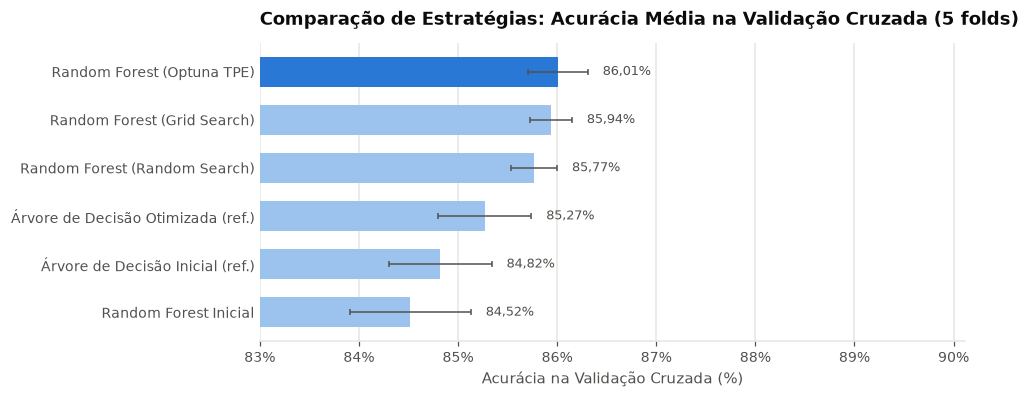

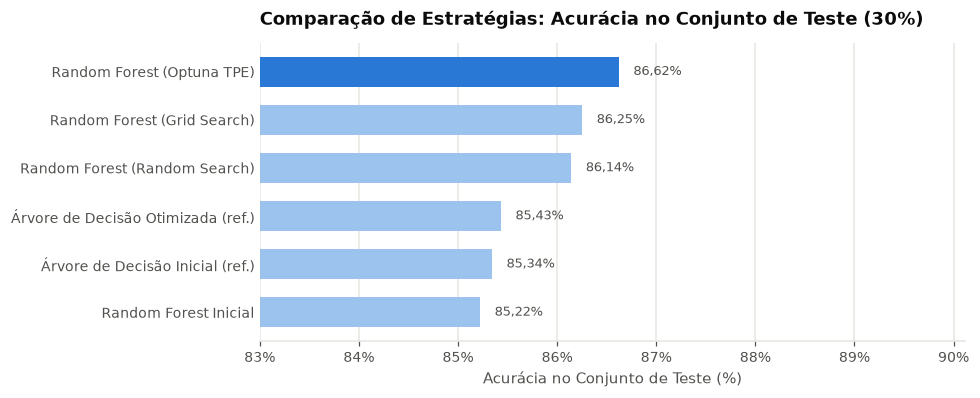

In [8]:
ROTULOS_ESTRATEGIA = {
    "grid_search": "Random Forest (Grid Search)",
    "random_search": "Random Forest (Random Search)",
    "optuna_tpe": "Random Forest (Optuna TPE)",
}

linhas_comp = [
    {
        "Estratégia": "Árvore de Decisão Inicial (ref.)",
        "Candidatos": 1,
        "Ajustes": comum.FOLDS,
        "Tempo (s)": round(cv_arvore_ini["tempo_total_s"], 1),
        "CV acurácia (%)": pct(cv_arvore_ini["acuracia"]),
        "CV ± (%)": pct(cv_arvore_ini["acuracia_std"]),
        "Teste acurácia (%)": pct(teste_arvore_ini["acuracia"]),
        "Teste F1 (%)": pct(teste_arvore_ini["f1"]),
        "Teste ROC-AUC (%)": pct(teste_arvore_ini["roc_auc"]),
        "Melhores parâmetros": comum.PARAMETROS_ARVORE_ANTERIOR,
    },
    {
        "Estratégia": "Árvore de Decisão Otimizada (ref.)",
        "Candidatos": melhor_exec_arv["n_candidatos"],
        "Ajustes": melhor_exec_arv["n_ajustes"],
        "Tempo (s)": round(melhor_exec_arv["tempo_s"], 1),
        "CV acurácia (%)": pct(cv_arvore_otim["acuracia"]),
        "CV ± (%)": pct(cv_arvore_otim["acuracia_std"]),
        "Teste acurácia (%)": pct(teste_arvore_otim["acuracia"]),
        "Teste F1 (%)": pct(teste_arvore_otim["f1"]),
        "Teste ROC-AUC (%)": pct(teste_arvore_otim["roc_auc"]),
        "Melhores parâmetros": PARAM_ARVORE_OTIM,
    },
    {
        "Estratégia": "Random Forest Inicial",
        "Candidatos": 1,
        "Ajustes": comum.FOLDS,
        "Tempo (s)": round(cv_ini["tempo_total_s"], 1),
        "CV acurácia (%)": pct(cv_ini["acuracia"]),
        "CV ± (%)": pct(cv_ini["acuracia_std"]),
        "Teste acurácia (%)": pct(teste_ini["acuracia"]),
        "Teste F1 (%)": pct(teste_ini["f1"]),
        "Teste ROC-AUC (%)": pct(teste_ini["roc_auc"]),
        "Melhores parâmetros": PARAM_RF,
    },
]

for e in saida["estrategias"]:
    linhas_comp.append({
        "Estratégia": ROTULOS_ESTRATEGIA.get(e["estrategia"], e["estrategia"]),
        "Candidatos": e["n_candidatos"],
        "Ajustes": e["n_ajustes"],
        "Tempo (s)": round(e["tempo_s"], 1),
        "CV acurácia (%)": pct(e["cv"]["acuracia"]),
        "CV ± (%)": pct(e["cv"]["acuracia_std"]),
        "Teste acurácia (%)": pct(e["teste"]["acuracia"]),
        "Teste F1 (%)": pct(e["teste"]["f1"]),
        "Teste ROC-AUC (%)": pct(e["teste"]["roc_auc"]),
        "Melhores parâmetros": e["melhores_parametros"],
    })

tab_estrategias = pd.DataFrame(linhas_comp).set_index("Estratégia")

# Seleção do melhor modelo pela acurácia exata na validação cruzada
candidatos_rf = {
    "modelo_inicial": (rf_inicial, cv_ini["acuracia"], PARAM_RF),
    "grid_search": (gs.best_estimator_, reg_gs["cv"]["acuracia"], reg_gs["melhores_parametros"]),
    "random_search": (rs.best_estimator_, reg_rs["cv"]["acuracia"], reg_rs["melhores_parametros"]),
    "optuna_tpe": (pipe_optuna, reg_optuna["cv"]["acuracia"], reg_optuna["melhores_parametros"]),
}
nome_melhor, (melhor, melhor_cv_acc, melhores_params_final) = max(
    candidatos_rf.items(), key=lambda item: item[1][1]
)
melhor.fit(X_tr, y_tr)
teste_final = comum.avaliar_teste(melhor, X_te, y_te)

saida["melhor_estrategia"] = nome_melhor
saida["melhores_parametros_final"] = melhores_params_final

print(f">>> Estratégia vencedora na validação cruzada: {nome_melhor} (CV Acurácia = {melhor_cv_acc*100:.2f}% | Teste Acurácia = {teste_final['acuracia']*100:.2f}%)")
display(tab_estrategias)

# Gráfico 1: Acurácia Média na Validação Cruzada (5 folds)
destaque_idx = ROTULOS_ESTRATEGIA.get(nome_melhor, "Random Forest Inicial")
grafico_metricas(
    tab_estrategias,
    metrica="CV acurácia (%)",
    erro="CV ± (%)",
    titulo="Comparação de Estratégias: Acurácia Média na Validação Cruzada (5 folds)",
    destaque=destaque_idx,
    xlabel="Acurácia na Validação Cruzada (%)",
    xmin=83.0,
)

# Gráfico 2: Acurácia no Conjunto de Teste (30%)
grafico_metricas(
    tab_estrategias,
    metrica="Teste acurácia (%)",
    erro=None,
    titulo="Comparação de Estratégias: Acurácia no Conjunto de Teste (30%)",
    destaque=destaque_idx,
    xlabel="Acurácia no Conjunto de Teste (%)",
    xmin=83.0,
)

In [9]:
# Comparação detalhada de todas as métricas no Conjunto de Teste
comparacao_teste = pd.DataFrame({
    "Árvore Inicial (%)": {NOMES_METRICAS[k]: pct(v) for k, v in teste_arvore_ini.items()},
    "Árvore Otimizada (%)": {NOMES_METRICAS[k]: pct(v) for k, v in teste_arvore_otim.items()},
    "RF Inicial (%)": {NOMES_METRICAS[k]: pct(v) for k, v in teste_ini.items()},
    "RF Final (%)": {NOMES_METRICAS[k]: pct(v) for k, v in teste_final.items()},
    "Ganho RF Final vs. RF Inicial (p.p.)": {
        NOMES_METRICAS[k]: round((teste_final[k] - teste_ini[k]) * 100, 2) for k in teste_ini
    },
    "Ganho RF Final vs. Árvore Inicial (p.p.)": {
        NOMES_METRICAS[k]: round((teste_final[k] - teste_arvore_ini[k]) * 100, 2) for k in teste_arvore_ini
    },
    "Ganho RF Final vs. Árvore Otimizada (p.p.)": {
        NOMES_METRICAS[k]: round((teste_final[k] - teste_arvore_otim[k]) * 100, 2) for k in teste_arvore_otim
    },
})
display(comparacao_teste)

y_pred_final = melhor.predict(X_te)
print("\nRelatório de Classificação no Conjunto de Teste (Random Forest Final):")
print(classification_report(y_te, y_pred_final, target_names=["≤ 50 mil", "> 50 mil"], digits=4))

,Árvore Inicial (%),Árvore Otimizada (%),RF Inicial (%),RF Final (%),Ganho RF Final vs. RF Inicial (p.p.),Ganho RF Final vs. Árvore Inicial (p.p.),Ganho RF Final vs. Árvore Otimizada (p.p.)
Acurácia,85.34,85.43,85.22,86.62,1.39,1.28,1.18
Acurácia balanceada,75.03,76.59,74.23,78.91,4.68,3.88,2.32
Precision (> 50 mil),80.30,77.16,81.81,78.63,-3.18,-1.67,1.46
Recall (> 50 mil),54.48,58.97,52.31,63.54,11.23,9.06,4.57
F1 (> 50 mil),64.92,66.85,63.81,70.28,6.47,5.36,3.43
ROC-AUC,90.34,90.34,90.66,92.16,1.50,1.82,1.82



Relatório de Classificação no Conjunto de Teste (Random Forest Final):
              precision    recall  f1-score   support

    ≤ 50 mil     0.8863    0.9427    0.9136      6790
    > 50 mil     0.7863    0.6354    0.7028      2252

    accuracy                         0.8662      9042
   macro avg     0.8363    0.7891    0.8082      9042
weighted avg     0.8614    0.8662    0.8611      9042



## 8. Curva de Validação: Número de Árvores (`n_estimators`) na Floresta Otimizada

Uma propriedade central do algoritmo Random Forest é que o aumento do número de árvores (`n_estimators`) reduz a variância das predições até atingir um patamar de convergência, sem provocar sobreajuste (*overfitting*).

Avaliamos a curva de validação variando `n_estimators` em `[10, 25, 50, 100, 200, 300, 500]` diretamente sobre a **Floresta Otimizada vencedora**, mantendo fixos os demais hiperparâmetros ótimos encontrados.

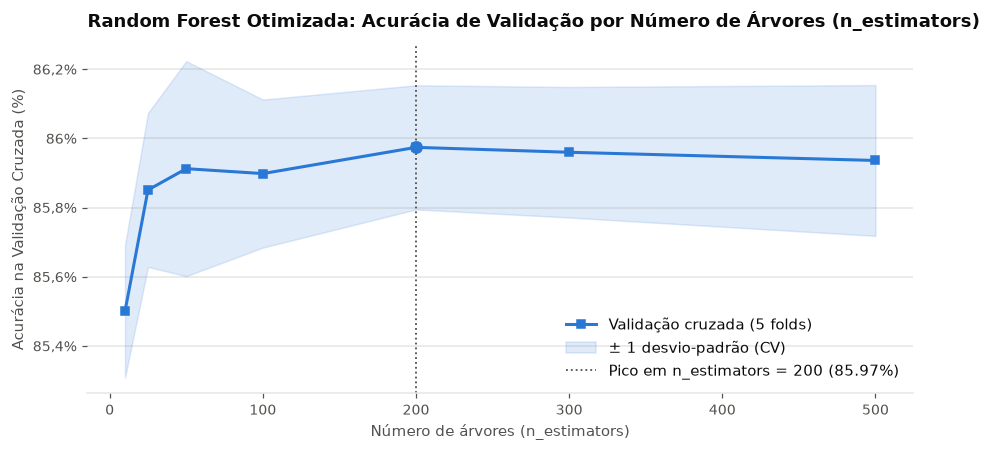

,Acurácia Treino (%),Acurácia Validação (%),Desvio Padrão CV (%)
n_estimators,,,
10,89.23,85.50,0.19
25,89.57,85.85,0.22
50,89.59,85.91,0.31
100,89.58,85.90,0.21
200,89.59,85.97,0.18
300,89.61,85.96,0.19
500,89.60,85.94,0.22


In [10]:
n_estimators_range = [10, 25, 50, 100, 200] if RAPIDO else [10, 25, 50, 100, 200, 300, 500]

tr_scores, val_scores = validation_curve(
    melhor,
    X_tr,
    y_tr,
    param_name="modelo__n_estimators",
    param_range=n_estimators_range,
    cv=cv,
    scoring="accuracy",
    n_jobs=N_JOBS,
)

saida["curva_validacao"] = {
    "n_estimators": n_estimators_range,
    "train_accuracy": tr_scores.mean(axis=1).tolist(),
    "valid_accuracy": val_scores.mean(axis=1).tolist(),
    "valid_accuracy_std": val_scores.std(axis=1).tolist(),
}

# Gráfico da Curva de Validação na Floresta Otimizada
fig, ax = plt.subplots(figsize=(8.5, 4.2))
tr_mean = tr_scores.mean(axis=1) * 100
val_mean = val_scores.mean(axis=1) * 100
val_std = val_scores.std(axis=1) * 100

ax.plot(n_estimators_range, val_mean, marker="s", ms=5, lw=2, color=AZUL, label="Validação cruzada (5 folds)")
ax.fill_between(n_estimators_range, val_mean - val_std, val_mean + val_std, color=AZUL, alpha=0.14, label="± 1 desvio-padrão (CV)")

melhor_idx = int(np.argmax(val_mean))
melhor_n = n_estimators_range[melhor_idx]
melhor_val = val_mean[melhor_idx]
ax.axvline(melhor_n, color=TEXTO_SEC, linestyle=":", linewidth=1.2, label=f"Pico em n_estimators = {melhor_n} ({melhor_val:.2f}%)")
ax.scatter([melhor_n], [melhor_val], color=AZUL, s=55, zorder=5)

ax.set_title("Random Forest Otimizada: Acurácia de Validação por Número de Árvores (n_estimators)")
ax.set_xlabel("Número de árvores (n_estimators)")
ax.set_ylabel("Acurácia na Validação Cruzada (%)")
ax.grid(axis="x", visible=False)
eixo_percentual(ax, "y")
ax.legend(loc="lower right")
plt.tight_layout()
mostrar()

tab_curva = pd.DataFrame({
    "n_estimators": n_estimators_range,
    "Acurácia Treino (%)": tr_mean.round(2),
    "Acurácia Validação (%)": val_mean.round(2),
    "Desvio Padrão CV (%)": val_std.round(2),
}).set_index("n_estimators")
display(tab_curva)

## 9. Análise de Erros: Matriz de Confusão e Curva ROC

Geramos a matriz de confusão (em contagens absolutas e normalizada por classe real) e a curva ROC no conjunto de teste para o melhor modelo de Random Forest, comparando sua curva ROC com a Random Forest Inicial, a Árvore de Decisão Otimizada e a Árvore de Decisão Inicial.

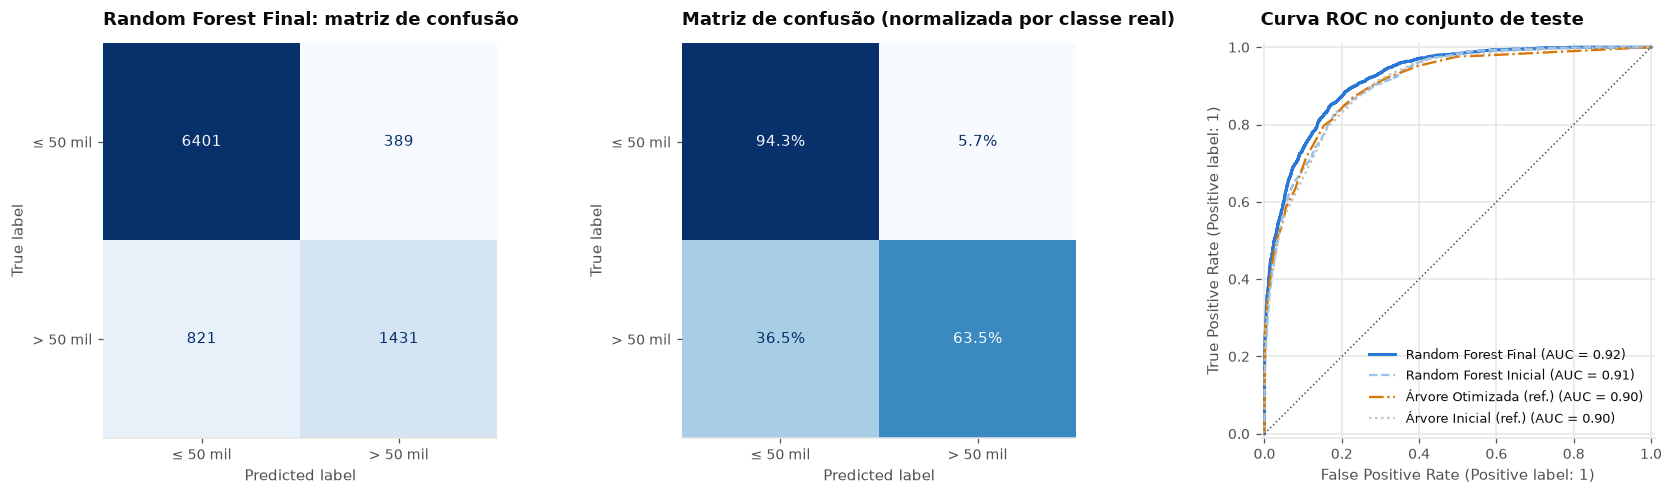

,Previsto ≤ 50 mil,Previsto > 50 mil
Real ≤ 50 mil,6401,389
Real > 50 mil,821,1431


In [11]:
saida["matriz_confusao"] = gerar_matriz_confusao(melhor, X_te, y_te)
saida["roc_auc"] = gerar_roc(melhor, X_te, y_te)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# 1. Matriz de confusão (contagens)
cm = confusion_matrix(y_te, y_pred_final)
ConfusionMatrixDisplay(cm, display_labels=["≤ 50 mil", "> 50 mil"]).plot(
    cmap="Blues", ax=axes[0], values_format="d", colorbar=False
)
axes[0].set_title("Random Forest Final: matriz de confusão")
axes[0].grid(False)

# 2. Matriz de confusão (normalizada por linha / classe real)
cmn = confusion_matrix(y_te, y_pred_final, normalize="true")
ConfusionMatrixDisplay(cmn, display_labels=["≤ 50 mil", "> 50 mil"]).plot(
    cmap="Blues", ax=axes[1], values_format=".1%", colorbar=False
)
axes[1].set_title("Matriz de confusão (normalizada por classe real)")
axes[1].grid(False)

# 3. Curva ROC comparativa
RocCurveDisplay.from_estimator(
    melhor, X_te, y_te, name="Random Forest Final", ax=axes[2], curve_kwargs={"color": AZUL, "linewidth": 2}
)
RocCurveDisplay.from_estimator(
    rf_inicial, X_te, y_te, name="Random Forest Inicial", ax=axes[2], curve_kwargs={"color": AZUL_CLARO, "linestyle": "--"}
)
RocCurveDisplay.from_estimator(
    arvore_otim, X_te, y_te, name="Árvore Otimizada (ref.)", ax=axes[2], curve_kwargs={"color": "#d97706", "linestyle": "-."}
)
RocCurveDisplay.from_estimator(
    arvore_inicial, X_te, y_te, name="Árvore Inicial (ref.)", ax=axes[2], curve_kwargs={"color": CINZA_OUTROS, "linestyle": ":"}
)
axes[2].plot([0, 1], [0, 1], linestyle=":", color=TEXTO_SEC, linewidth=1)
axes[2].set_title("Curva ROC no conjunto de teste")
axes[2].legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
mostrar()

tab_cm = pd.DataFrame(
    cm,
    index=pd.Index(["Real ≤ 50 mil", "Real > 50 mil"]),
    columns=["Previsto ≤ 50 mil", "Previsto > 50 mil"],
)
display(tab_cm)

## 10. Importância dos Atributos

Avaliamos a importância dos 12 atributos originais sob duas perspectivas complementares:
1. **Importância por Impureza de Gini (`feature_importances_` / MDI):** soma a redução média ponderada de impureza proporcionada pelas colunas de cada atributo original em todas as árvores da floresta.
2. **Importância por Permutação no Conjunto de Teste (`permutation_importance`):** mede a queda média na acurácia de teste (em pontos percentuais) quando os valores de um atributo original são embaralhados aleatoriamente (10 repetições), exatamente como feito para a Árvore Final no relatório anterior.

,Queda de acurácia por permutação (p.p.),Desvio padrão permutação (p.p.),Importância Gini (%)
ganho_capital,4.710,0.159,17.277
escolaridade_num,3.862,0.388,14.854
estado_civil,3.765,0.229,17.665
relacao_familiar,2.273,0.203,10.603
idade,2.086,0.200,13.632
ocupacao,1.283,0.165,5.629
perda_capital,1.244,0.105,4.868
horas_semana,0.951,0.131,7.917
sexo,0.206,0.079,1.526
pais_origem,0.090,0.082,1.936


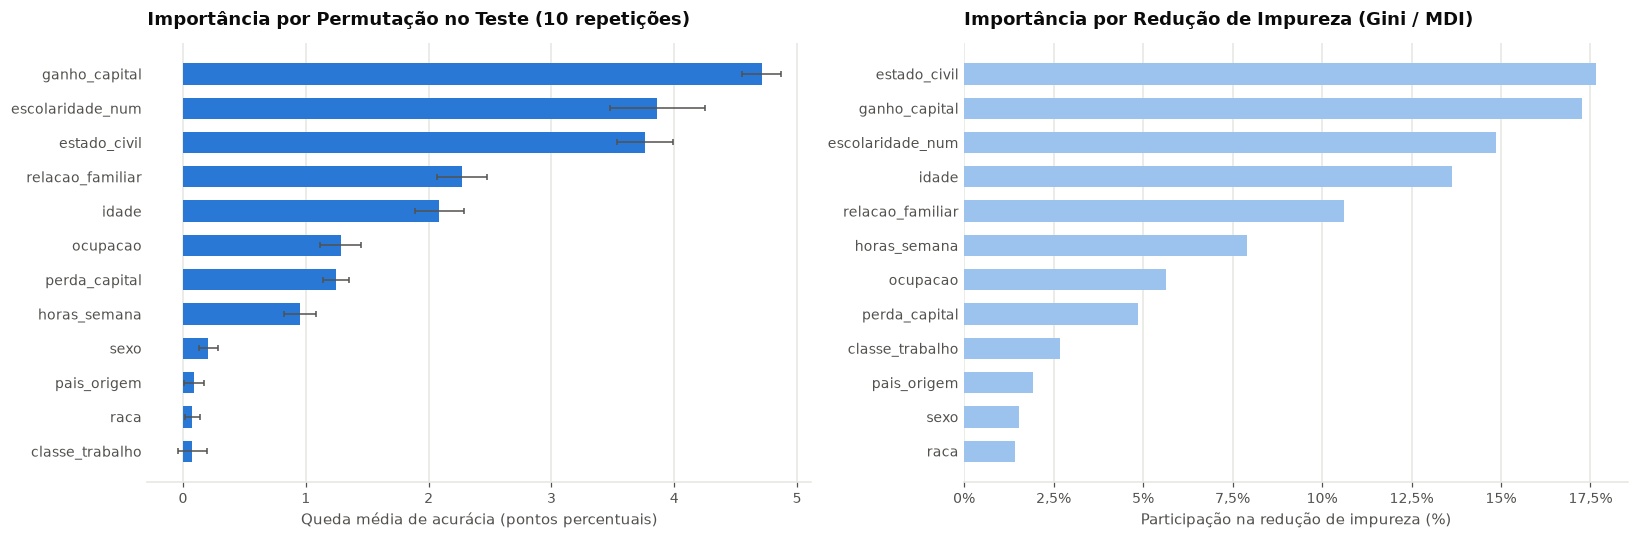

In [12]:
# 10.1 Importância por Impureza de Gini (agregada por atributo original)
imp_gini = gerar_importancias(melhor, X_originais=X_tr)
saida["importancias"] = imp_gini

# 10.2 Importância por Permutação no conjunto de teste
perm = permutation_importance(
    melhor,
    X_te,
    y_te,
    scoring="accuracy",
    n_repeats=10,
    random_state=comum.SEED,
    n_jobs=N_JOBS,
)

tab_imp = pd.DataFrame({
    "Queda de acurácia por permutação (p.p.)": perm.importances_mean * 100,
    "Desvio padrão permutação (p.p.)": perm.importances_std * 100,
    "Importância Gini (%)": pd.Series(imp_gini) * 100,
}, index=X_te.columns).sort_values("Queda de acurácia por permutação (p.p.)", ascending=False)

saida["importancias_permutacao"] = [
    {
        "atributo": attr,
        "queda_pp": float(row["Queda de acurácia por permutação (p.p.)"]),
        "std_pp": float(row["Desvio padrão permutação (p.p.)"]),
        "gini_pct": float(row["Importância Gini (%)"]),
    }
    for attr, row in tab_imp.iterrows()
]

display(tab_imp.round(3))

# Gráficos lado a lado: Permutação vs. Impureza de Gini
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ordem_perm = tab_imp.index[::-1]
axes[0].barh(
    ordem_perm,
    tab_imp.loc[ordem_perm, "Queda de acurácia por permutação (p.p.)"],
    xerr=tab_imp.loc[ordem_perm, "Desvio padrão permutação (p.p.)"],
    color=AZUL,
    height=0.62,
    error_kw={"ecolor": TEXTO_SEC, "capsize": 2, "elinewidth": 1},
)
axes[0].tick_params(axis="y", length=0)
axes[0].grid(axis="y", visible=False)
axes[0].set_title("Importância por Permutação no Teste (10 repetições)")
axes[0].set_xlabel("Queda média de acurácia (pontos percentuais)")

ordem_gini = tab_imp.sort_values("Importância Gini (%)", ascending=True).index
axes[1].barh(
    ordem_gini,
    tab_imp.loc[ordem_gini, "Importância Gini (%)"],
    color=AZUL_CLARO,
    height=0.62,
)
axes[1].tick_params(axis="y", length=0)
axes[1].grid(axis="y", visible=False)
axes[1].set_title("Importância por Redução de Impureza (Gini / MDI)")
axes[1].set_xlabel("Participação na redução de impureza (%)")
eixo_percentual(axes[1], "x")

plt.tight_layout()
mostrar()

## 11. Persistência dos Resultados

Salvamos todos os resultados do experimento no arquivo `resultados/random_forest.json` e as tabelas de melhores candidatos das três estratégias de busca (`Grid Search`, `Random Search` e `Optuna TPE`) em CSV para manter rastreabilidade e reprodutibilidade completas.

In [13]:
caminho_json = comum.salvar_resultado("random_forest", saida)
comum.salvar_tabela("random_forest_grade_top", comum.resumo_busca(gs, 20))
comum.salvar_tabela("random_forest_aleatoria_top", comum.resumo_busca(rs, 20))
comum.salvar_tabela("random_forest_optuna_top", df_optuna_top.head(20))

comum.log(f"Concluído com sucesso! Arquivo salvo em: {caminho_json}")

[11:12:06] Concluído com sucesso! Arquivo salvo em: C:\Users\luisfcabral\Documents\Projetos\UFPI\ML\PPGCC_Machine_Learning\resultados\random_forest.json
